
## 1. Import Libraries and Select Device

In [2]:
from torchvision import datasets            #helps is data loading
import torchvision.transforms as transforms 

from torch.utils.data import Dataset, DataLoader, Subset#helps in model build up and making a deep learning pipeline
import torch
import torch.nn as nn

import numpy as np # basic calculation
import matplotlib.pyplot as plt # visualization
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Dataset Path 

In [3]:
path = '/kaggle/input/datasets/farahibnat/dataset/Orginal Data'
print("Classes found:", __import__('os').listdir(path))

Classes found: ['Almond', 'Cashew', 'Peanuts', 'Pistachio']


## 3. Data Loading and Preprocessing
- **Resize** all images to 32×32 so they match the CNN input size.
- **Training augmentation** (random flip, ±15° rotation, color jitter) makes the model more robust and reduces overfitting. Validation/test images only get resize + `ToTensor`.
- The dataset has **no ready-made split**, so it is split randomly into **70% train / 15% validation / 15% test** (fixed seed 42 for reproducibility).

In [4]:
size = 32
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Same folder loaded twice: one with augmentation (train), one without (val/test)
full_train = datasets.ImageFolder(path, transform = train_transform)
full_eval  = datasets.ImageFolder(path, transform = val_transform)

# This dataset has no ready-made split, so split it 70% train / 15% validation / 15% test
total = len(full_train)
train_size = int(0.70 * total)
val_size = int(0.15 * total)
test_size = total - train_size - val_size

g = torch.Generator().manual_seed(42)
indices = torch.randperm(total, generator=g).tolist()

train_data = Subset(full_train, indices[:train_size])
val_data   = Subset(full_eval,  indices[train_size:train_size + val_size])
test_data  = Subset(full_eval,  indices[train_size + val_size:])

### Dataset Summary
Number of images in each split and the class-to-index mapping.


In [5]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , full_train.class_to_idx)

Dataset Summary
Train Data:  3073
Validation Data:  658
Test Data:  659
Classess and Indices:  {'Almond': 0, 'Cashew': 1, 'Peanuts': 2, 'Pistachio': 3}


## 4. Hyperparameters and Rationale
| Hyperparameter | Value | Rationale |
|---|---|---|
| Image size | 32×32 | Small input keeps training fast |
| Batch size | 32 | Balance between stable gradients and memory use |
| Learning rate | 1e-3 | Standard, safe starting value for Adam |
| Epochs | 10 | Enough for the loss to settle without long training time |
| Optimizer | Adam | Adaptive learning rate, converges faster than plain SGD |
| Loss | Cross-Entropy | Standard loss for multi-class classification |

In [6]:
batch_size = 32
learning_rate=1e-3
epoch_number = 10

## 5. Data Loaders
Data loaders feed images to the model in batches. Training data is **shuffled** each epoch; validation and test data are not.

In [7]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 6. Model Architecture (Custom CNN)
- **Feature extraction:** 3 × [Conv2d (3×3) → ReLU → MaxPool(2)], with **64 → 128 → 256** 
- Image size through the network: 32 → 30 → 15 → 13 → 6 → 4 → 2, so the last feature map is 256 × 2 × 2.
- **Classifier:** Flatten → Linear(256·2·2, **512**) → ReLU → Linear(512, **4**). 
- The final layer has 4 outputs, one per nut class.
- **Loss:** CrossEntropyLoss, **Optimizer:** Adam.

In [8]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(128, 256, kernel_size=3),   
        nn.ReLU(),
        nn.MaxPool2d(2), 

    #     #Classifier
    #     nn.Flatten(),
    #     nn.Linear(128*6*6, 256),
    #     nn.ReLU(),
    #     nn.Linear(256, 4)          # 4 classes: Almond, Cashew, Peanut, Pistachio
    # ).to(device)

    #Classifier
        nn.Flatten(),
        nn.Linear(256*2*2, 512),
        nn.ReLU(),
        nn.Linear(512, 4)          # 4 classes: Almond, Cashew, Peanuts, Pistachio
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

## 7. Training and Validation Functions
`train_one_epoch` updates the weights (forward pass → loss → backpropagation → optimizer step). `validation` only measures loss and accuracy without updating weights.


In [9]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

## 8. Model Summary
Layer-by-layer structure and a detailed summary (output shapes and parameter counts).

In [10]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
            Conv2d-7            [-1, 256, 4, 4]         295,168
              ReLU-8            [-1, 256, 4, 4]               0
         MaxPool2d-9            [-1, 256, 2, 2]               0
          Flatten-10                 [-1, 1024]               0
           Linear-11                  [-1, 512]         524,800
             ReLU-12                  [-1, 512]               0
           Linear-13                    [-1, 4]           2,052
Total params: 897,668
Trainable params:

## 9. Training Loop
Each epoch trains on the training set and then checks the validation set; loss and accuracy are recorded for plotting.

In [11]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.3616 | Train Accuracy: 28.02% | Val Loss: 1.3235 | Val Accuracy: 33.74%
Epoch [2/10] | Train Loss: 1.0704 | Train Accuracy: 49.24% | Val Loss: 0.8103 | Val Accuracy: 63.22%
Epoch [3/10] | Train Loss: 0.8273 | Train Accuracy: 63.07% | Val Loss: 0.6546 | Val Accuracy: 69.45%
Epoch [4/10] | Train Loss: 0.6790 | Train Accuracy: 71.82% | Val Loss: 0.5536 | Val Accuracy: 78.42%
Epoch [5/10] | Train Loss: 0.5429 | Train Accuracy: 78.78% | Val Loss: 0.4735 | Val Accuracy: 80.09%
Epoch [6/10] | Train Loss: 0.4177 | Train Accuracy: 83.11% | Val Loss: 0.6658 | Val Accuracy: 70.82%
Epoch [7/10] | Train Loss: 0.4084 | Train Accuracy: 84.87% | Val Loss: 0.4601 | Val Accuracy: 83.28%
Epoch [8/10] | Train Loss: 0.2922 | Train Accuracy: 88.94% | Val Loss: 0.1076 | Val Accuracy: 96.20%
Epoch [9/10] | Train Loss: 0.2017 | Train Accuracy: 92.16% | Val Loss: 0.2173 | Val Accuracy: 90.58%
Epoch [10/10] | Train Loss: 0.2019 | Train Accuracy: 92.84% | Val Loss: 0.1432 | Val Accura

## 10. Training and Validation Curves


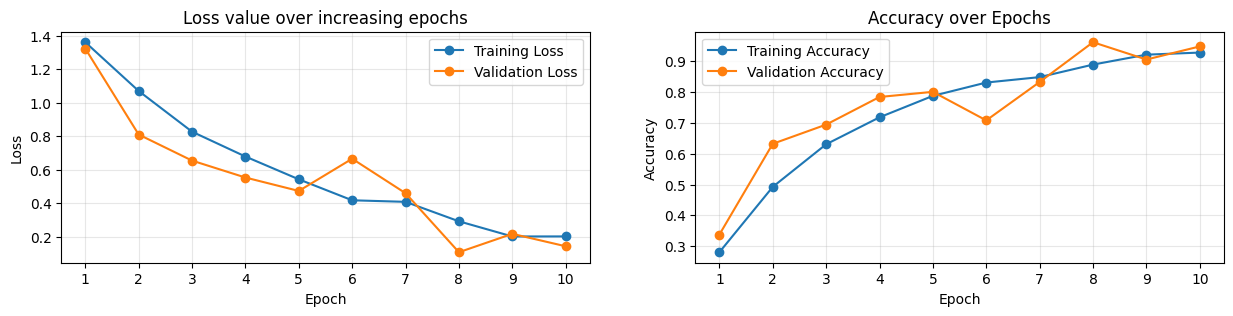

In [12]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Single Image Prediction
Predict one test image and show the predicted class with its confidence.


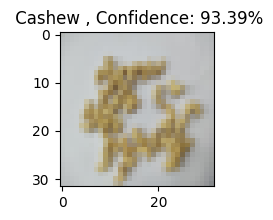

In [13]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {full_train.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

## 12. Evaluation on the Test Set
Final loss and accuracy on data the model never saw during training.

In [14]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.17 , Test Accuracy: 92.72%


### Detailed Metrics
Precision, recall and F1-score for each class, and the confusion matrix.



              precision    recall  f1-score   support

      Almond       0.88      0.99      0.93       144
      Cashew       0.99      0.98      0.99       171
     Peanuts       1.00      0.78      0.88       176
   Pistachio       0.85      0.97      0.91       168

    accuracy                           0.93       659
   macro avg       0.93      0.93      0.93       659
weighted avg       0.94      0.93      0.93       659



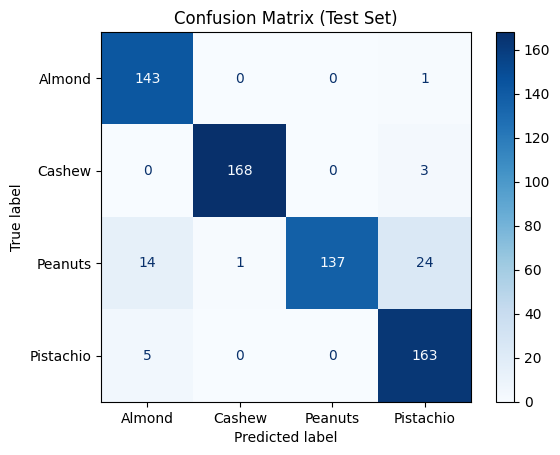

In [15]:
# Detailed test metrics: precision, recall, F1-score per class + confusion matrix
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        all_preds.extend(model(x).argmax(-1).cpu().tolist())
        all_labels.extend(y.tolist())

print(classification_report(all_labels, all_preds, target_names=full_train.classes))

ConfusionMatrixDisplay(confusion_matrix(all_labels, all_preds),
                       display_labels=full_train.classes).plot(cmap='Blues')
plt.title("Confusion Matrix (Test Set)")
plt.show()

## 13. Save the Trained Model Weights
Only the learned weights (`state_dict`) are saved to `model.pth`, so the model can be reused without retraining.


In [16]:
## Save the trained model ###
torch.save(model.state_dict(),'model.pth')

## 14. Load the Saved Model
Create a new model with the same architecture, load the saved weights, and verify it gives the same test accuracy.

In [17]:
## Load the saved model ###
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()
summary(saved_model,(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
            Conv2d-7            [-1, 256, 4, 4]         295,168
              ReLU-8            [-1, 256, 4, 4]               0
         MaxPool2d-9            [-1, 256, 2, 2]               0
          Flatten-10                 [-1, 1024]               0
           Linear-11                  [-1, 512]         524,800
             ReLU-12                  [-1, 512]               0
           Linear-13                    [-1, 4]           2,052
Total params: 897,668
Trainable params:

## 15. Check loaded model on the test set

In [18]:
## Check loaded model on the test set ###
test_loss, test_acc =  validation(test_dl,saved_model,loss_fn)
print(f'Loaded Model -> Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Loaded Model -> Test Loss : 0.17 , Test Accuracy: 92.72%


## 16. Analysis and Discussion of Results

**Overall performance:** The custom CNN reached **93.32% test accuracy** (test loss 0.18), close to the final validation accuracy of 94.53%. This shows the model generalizes well. The reloaded model gave identical results, so saving and loading worked correctly.

**Training behaviour:**
- Training accuracy rose from 29.42% to 89.78% over 10 epochs, and training loss fell from 1.35 to 0.28.
- Validation accuracy was unstable in epochs 3–7 (57–73%) before jumping to about 95% at epoch 8. Likely causes are the fixed learning rate, no BatchNorm, and the small 32×32 input.
- Validation and test accuracy are higher than training accuracy because only the training images are augmented. There is no sign of overfitting, since validation loss did not rise.

**Per-class results:**

| Class | Precision | Recall | F1 |
|---|---|---|---|
| Almond | 0.99 | 0.94 | 0.96 |
| Cashew | 0.97 | 0.99 | 0.98 |
| Peanuts | 0.98 | 0.82 | 0.89 |
| Pistachio | 0.83 | 0.99 | 0.91 |

Cashew and Almond are recognized best. The main error is **Peanuts being predicted as Pistachio**, which lowers Peanuts recall and Pistachio precision. A likely reason is that resizing to 32×32 removes fine texture details that separate these two classes.

## 17. Conclusions and Future Work

**Conclusions:**
- A simple three-block CNN trained from scratch classified four nut types with **93.32% test accuracy** (macro F1 = 0.93) using only 32×32 images and 10 epochs.
- Augmentation helped generalization, and validation and test results were consistent.
- The weakest point is the Peanuts–Pistachio confusion.

**Future work:**
1. Use a higher input resolution (64×64 or 128×128) to keep more texture detail.
2. Add BatchNorm and Dropout, and use a learning rate scheduler with early stopping to stabilize training.
3. Train for more epochs, since training accuracy was still improving.
4. Fine-tune a pretrained model such as ResNet18 or MobileNetV2.
5. Add more Peanuts and Pistachio images or stronger augmentation for these classes.